<a href="https://colab.research.google.com/github/danielaceves5162/Tareas_TS_Aceves_Daniel/blob/main/HW5_Aceves_Daniel.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#  $${HOMEWORK \ 5}$$


**Alumno:** Aceves Maya Christopher Daniel

**Asignatura:** Temas selectos de ingenieria

---
**Tarea 5:**

$$ Modelos \ de \ regresión \ y \ estandarización \ de \ datos $$

---

Fecha: 15/10/2026

Profesor: Dr. Moises  Velasco  Lozano

###INTRODUCCIÓN Y TEORÍA

En la industria petrolera, predecir el comportamiento dinámico de un pozo (como su tasa de producción) requiere analizar múltiples variables estáticas y dinámicas simultáneamente. Por ejemplo, en los campos maduros del Activo Integral Ku-Maloob-Zaap, la producción depende de la porosidad, la permeabilidad, el espesor disparado y la presión del yacimiento.

El problema radica en que estas propiedades tienen **magnitudes y unidades completamente diferentes**. La presión puede estar en miles de psi, mientras que la porosidad es una fracción menor a 1. Modelos de regresión lineal simple pueden verse sesgados por las escalas; y los modelos con penalización o regularización, como **Ridge Regression**, son extremadamente sensibles a esto, ya que penalizan los coeficientes grandes.

Para evitar sesgos y comparar el peso real de cada variable, aplicamos la **estandarización** (Z-score). Esto centra los datos en una media de cero y desviación estándar de uno.

---
**Glosario Técnico:**
* **Linear Regression:** Modelo matemático que busca una relación lineal (un hiperplano) entre variables independientes y una dependiente minimizando los residuos cuadrados.
* **Ridge Regression (Regresión Contraída):** Variante de la regresión lineal que incorpora una penalización $L2$ (hiperparámetro $\alpha$) para evitar el sobreajuste (overfitting) cuando existe multicolinealidad.
* **Estandarización:** Transformación estadística que elimina las unidades físicas de las variables para ponerlas en una escala relativa comparable.

---

### Preparación de los datos

A continuación vamos a definir nuestro *DataFrame* con 6 variables independientes y nuestra variable objetivo (producción).

In [ ]:
try:
    import sklearn
except ModuleNotFoundError:
    %pip install scikit-learn -q
    import sklearn

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn

In [ ]:
# Cargamos los datos para imprimir los primeros 5
df = pd.read_csv('https://raw.githubusercontent.com/GeostatsGuy/GeoDataSets/master/unconv_MV_v4.csv')

# sacamos estadísticas de los datos
df.describe()
# identificamos las variables
print("Primeras 5 filas del dataset:")
display(df.head())

columnas_x = df.columns[:7]
columna_y = df.columns[7]

X = df[columnas_x]
y = df[columna_y]


print(f"\nVariables independientes (X): {list(columnas_x)}")
print(f"Variable objetivo (y): {columna_y}")
print(X)
print(y)

Primeras 5 filas del dataset:


,Well,Por,Perm,AI,Brittle,TOC,VR,Prod
0,1,12.08,2.92,2.80,81.40,1.16,2.31,1695.360819
1,2,12.38,3.53,3.22,46.17,0.89,1.88,3007.096063
2,3,14.02,2.59,4.01,72.80,0.89,2.72,2531.938259
3,4,17.67,6.75,2.63,39.81,1.08,1.88,5288.514854
4,5,17.52,4.57,3.18,10.94,1.51,1.90,2859.469624



Variables independientes (X): ['Well', 'Por', 'Perm', 'AI', 'Brittle', 'TOC', 'VR']
Variable objetivo (y): Prod
     Well    Por  Perm    AI  Brittle   TOC    VR
0       1  12.08  2.92  2.80    81.40  1.16  2.31
1       2  12.38  3.53  3.22    46.17  0.89  1.88
2       3  14.02  2.59  4.01    72.80  0.89  2.72
3       4  17.67  6.75  2.63    39.81  1.08  1.88
4       5  17.52  4.57  3.18    10.94  1.51  1.90
..    ...    ...   ...   ...      ...   ...   ...
195   196  11.95  3.13  2.97    67.18  0.80  2.06
196   197  17.99  9.87  3.38    44.32  0.98  2.08
197   198  12.12  2.27  3.52    57.07 -0.04  1.73
198   199  15.55  4.48  2.48    58.25  1.89  2.35
199   200  20.89  7.54  3.23    46.17  1.71  2.27

[200 rows x 7 columns]
0      1695.360819
1      3007.096063
2      2531.938259
3      5288.514854
4      2859.469624
          ...     
195    2203.839738
196    5949.843842
197    2701.389046
198    4415.829234
199    8590.384044
Name: Prod, Length: 200, dtype: float64


### con una observación simple determinamos la variable con más relación

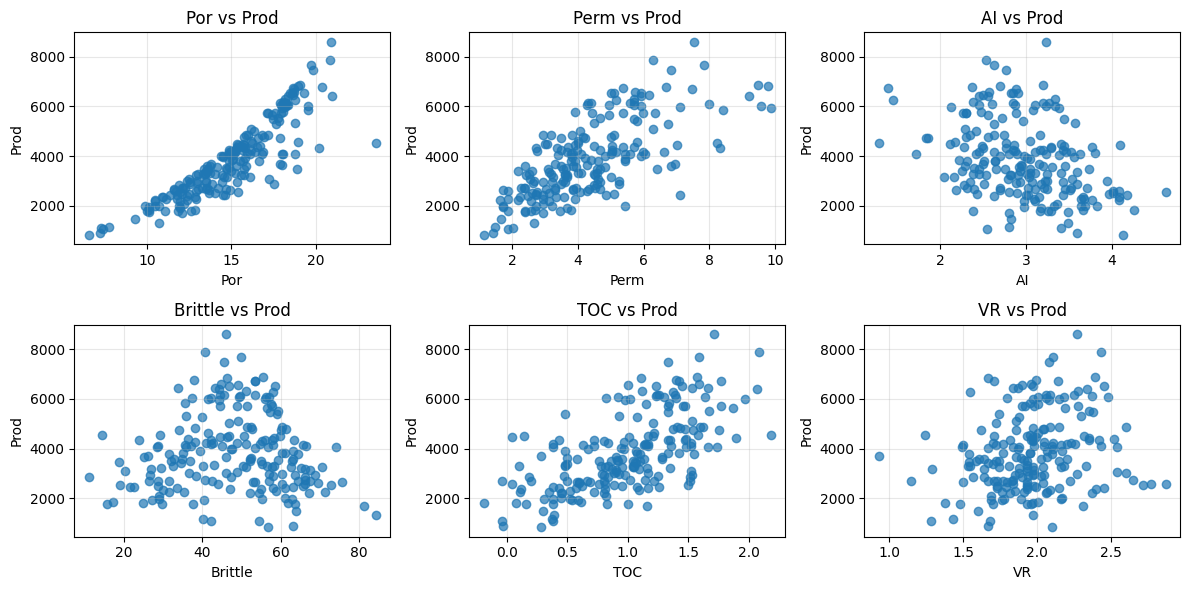

In [ ]:
# Production (Prod) y = df[columna_y]
y = df[columna_y]

# 2 rows × 3 columns
fig, axes = plt.subplots(2, 3, figsize=(12, 6))

# Transform axes into 1D array
axes = axes.flatten()

for i in range(6):

    x = df.iloc[:, i+1]

    axes[i].scatter(x, y, alpha=0.7)

    axes[i].set_xlabel(df.columns[i+1])
    axes[i].set_ylabel(df.columns[7])
    axes[i].set_title(f"{df.columns[i+1]} vs {df.columns[7]}")

    axes[i].grid(alpha=0.3)

plt.tight_layout()
plt.show()

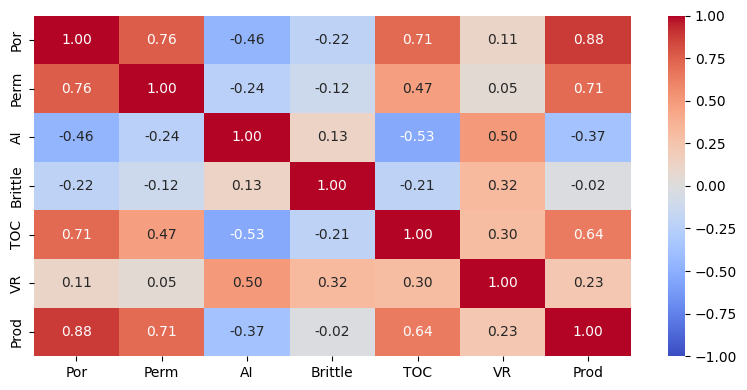

In [ ]:
corr = df.iloc[:, 1:].corr()

plt.figure(figsize=(8, 4))

sns.heatmap(corr,annot=True,fmt=".2f",cmap="coolwarm",vmin=-1,vmax=1)

plt.tight_layout()
plt.show()

### Actividad 1. Regresión lineal

El modelo de regresión lineal múltiple obedece la siguiente ecuación:
$$y = \beta_0 + \beta_1 X_1 + \beta_2 X_2 + \dots + \beta_6 X_6$$

Luego usaremos la estandarización manual en las variables independientes usando la media ($\mu$) y la desviación estándar ($\sigma$) obtenidas del conjunto de **entrenamiento** (para evitar *data leakage*):

$$Z = \frac{X - \mu}{\sigma}$$

In [ ]:
# import library to split data
from sklearn.model_selection import train_test_split

# Set input and output features
columnas_x = df.columns[1:7]
columna_y = df.columns[7]

X = df[columnas_x]
y = df[columna_y]

# Split data into training and testing
X_train, X_test, y_train, y_test = train_test_split(X, y,test_size=0.20,random_state=42)

print(X_train.shape)
print(X_test.shape)
print(y_train.shape)
print(y_test.shape)

(160, 6)
(40, 6)
(160,)
(40,)


In [ ]:
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error
from sklearn.linear_model import LinearRegression

# 2. Dividir los datos en entrenamiento y prueba (80% - 20%)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 3. Entrenar modelo con variables originales
modelo_rl = LinearRegression()
modelo_rl.fit(X_train, y_train)

# 4. Estandarización manual de las 6 variables
mu = X_train.mean()
sigma = X_train.std(ddof=1)

X_train_std = (X_train - mu) / sigma
X_test_std = (X_test - mu) / sigma

# 5. Entrenar modelo con variables estandarizadas
modelo_rl_stand = LinearRegression()
modelo_rl_stand.fit(X_train_std, y_train)

LinearRegression()

In [ ]:
print("=x"*40+"\n")
print(modelo_rl.intercept_)
print(modelo_rl.coef_)
print("\n"+"=x"*40+"\n")
print(modelo_rl_stand.intercept_)
print(modelo_rl_stand.coef_)
print("\n"+"=x"*40+"\n")


# 6. Obtener e interpretar coeficientes
df_coef_rl = pd.DataFrame({
    'Variable': X.columns,
    'Coef_Originales': modelo_rl.coef_,
    'Coef_Estandarizados': modelo_rl_stand.coef_
})
display(df_coef_rl)

=x=x=x=x=x=x=x=x=x=x=x=x=x=x=x=x=x=x=x=x=x=x=x=x=x=x=x=x=x=x=x=x=x=x=x=x=x=x=x=x

-3976.390998388353
[ 423.96977071   84.27824416 -164.10221643   14.06258161   -6.94135448
  485.89411887]

=x=x=x=x=x=x=x=x=x=x=x=x=x=x=x=x=x=x=x=x=x=x=x=x=x=x=x=x=x=x=x=x=x=x=x=x=x=x=x=x

3895.8430096087504
[1263.49943752  148.96570638  -92.07924261  195.37912265   -3.33315913
  147.83292125]

=x=x=x=x=x=x=x=x=x=x=x=x=x=x=x=x=x=x=x=x=x=x=x=x=x=x=x=x=x=x=x=x=x=x=x=x=x=x=x=x



,Variable,Coef_Originales,Coef_Estandarizados
0,Por,423.969771,1263.499438
1,Perm,84.278244,148.965706
2,AI,-164.102216,-92.079243
3,Brittle,14.062582,195.379123
4,TOC,-6.941354,-3.333159
5,VR,485.894119,147.832921


--- MÉTRICAS LINEAR REGRESSION (Datos Originales) ---
R²   = 0.783
MAE  = 482.67 mD
RMSE = 681.52 mD

--- MÉTRICAS LINEAR REGRESSION (Datos Estandarizados) ---
R²   = 0.783
MAE  = 482.67 mD
RMSE = 681.52 mD


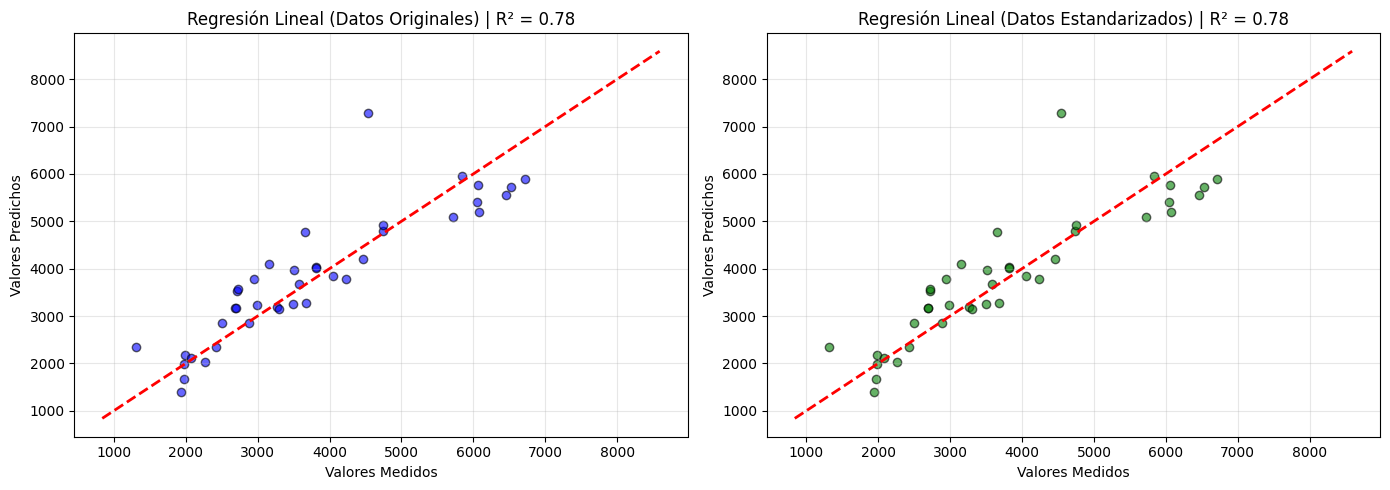

In [ ]:
# 7. Generar predicciones para el conjunto de prueba
y_pred_orig = modelo_rl.predict(X_test)
y_pred_std = modelo_rl_stand.predict(X_test_std)

# 8. Evaluar ambos modelos con las métricas de clase
print("--- MÉTRICAS LINEAR REGRESSION (Datos Originales) ---")
r2_orig = r2_score(y_test, y_pred_orig)
mae_orig = mean_absolute_error(y_test, y_pred_orig)
rmse_orig = np.sqrt(mean_squared_error(y_test, y_pred_orig))
print("R²   =", round(r2_orig, 3))
print("MAE  =", round(mae_orig, 2), "mD")
print("RMSE =", round(rmse_orig, 2), "mD\n")

print("--- MÉTRICAS LINEAR REGRESSION (Datos Estandarizados) ---")
r2_std = r2_score(y_test, y_pred_std)
mae_std = mean_absolute_error(y_test, y_pred_std)
rmse_std = np.sqrt(mean_squared_error(y_test, y_pred_std))
print("R²   =", round(r2_std, 3))
print("MAE  =", round(mae_std, 2), "mD")
print("RMSE =", round(rmse_std, 2), "mD")

# 9. Elaborar gráficas de valores medidos vs predichos
fig, axs = plt.subplots(1, 2, figsize=(14, 5))

axs[0].scatter(y_test, y_pred_orig, color='blue', alpha=0.6, edgecolor='k')
axs[0].plot([y.min(), y.max()], [y.min(), y.max()], 'r--', lw=2)
axs[0].set_title(f'Regresión Lineal (Datos Originales) | R² = {r2_orig:.2f}')
axs[0].set_xlabel('Valores Medidos')
axs[0].set_ylabel('Valores Predichos')
axs[0].grid(alpha=0.3)

axs[1].scatter(y_test, y_pred_std, color='green', alpha=0.6, edgecolor='k')
axs[1].plot([y.min(), y.max()], [y.min(), y.max()], 'r--', lw=2)
axs[1].set_title(f'Regresión Lineal (Datos Estandarizados) | R² = {r2_std:.2f}')
axs[1].set_xlabel('Valores Medidos')
axs[1].set_ylabel('Valores Predichos')
axs[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

### análisis, predicciones y evaluación de la actividad 1

**Análisis de Regresión Lineal:**
El desempeño predictivo ($R^2$ y $MSE$) de ambos modelos es *matemáticamente idéntico*. La estandarización no mejora el poder predictivo en la Regresión Lineal ordinaria.
Sin embargo, la **interpretación de los coeficientes cambia drásticamente**. En los datos originales, la Presión ($X_3$) tiene un coeficiente bajo porque se mueve en miles, y el Skin ($X_6$) tiene uno mucho más alto porque varía apenas en unidades. En el modelo estandarizado, los coeficientes ahora dictan la **importancia real** de cada variable; todos "se comunican en el mismo idioma" de desviaciones estándar. Un coeficiente de 150 en la Presión estandarizada significa que por cada desviación estándar que suba la presión, la producción subirá 150 unidades.

## Actividad 2. Ridge Regression

Ridge introduce una penalización a la magnitud de los coeficientes para evitar la multicolinealidad. La función de pérdida a minimizar se convierte en:
$$L = \sum_{i=1}^{n} (y_i - \hat{y}_i)^2 + \alpha \sum_{j=1}^{p} \beta_j^2$$

Luego usaremos la estandarización manual en las variables independientes usando la media ($\mu$) y la desviación estándar ($\sigma$) obtenidas del conjunto de **entrenamiento** (para evitar *data leakage*):

$$Z = \frac{X - \mu}{\sigma}$$

##Data splitting

In [ ]:
# importamos librerías para el split data
from sklearn.model_selection import train_test_split

# introducimos las input y output features
columnas_x = df.columns[1:7]
columna_y = df.columns[7]

X = df[columnas_x]
y = df[columna_y]

# primer split: 80% train, 20% val+test

X_train, X_mask, y_train, y_mask = train_test_split(X,y,test_size=0.20,random_state=2)

# segundo split: 10% train, 10% validation

X_val, X_test, y_val, y_test = train_test_split(X_mask,y_mask,test_size=0.50,random_state=20)

print("valores de X \n")
print("Train shape:\t", X_train.shape)
print("Validation shape:", X_val.shape)
print("Test shape:\t", X_test.shape)
print("="*28)
print("\n valores de Y \n")
print("Train shape:\t", y_train.shape)
print("Validation shape:", y_val.shape)
print("Test shape:\t", y_test.shape)

valores de X 

Train shape:	 (160, 6)
Validation shape: (20, 6)
Test shape:	 (20, 6)

 valores de Y 

Train shape:	 (160,)
Validation shape: (20,)
Test shape:	 (20,)


###Definimos el hiperparametro alpha

In [ ]:
alphas = [ 0.0001, 0.001,0.1 , 1, 10 , 100 , 1000 ]

	 --- RESULTADOS DE VALIDACIÓN MANUAL CORREGIDOS ---

=x=x=x=x=x=x=x=x=x=x=x=x=x=x=x=x=x=x=x=x=x=x=x=x=x=x=x=x=x=x=x=x=x=x=x=x=x=x=x=x

Alpha: 0.0001   | RMSE Orig: 792.37 | RMSE Std: 792.37
Alpha: 0.001    | RMSE Orig: 792.33 | RMSE Std: 792.37
Alpha: 0.1      | RMSE Orig: 788.72 | RMSE Std: 792.13
Alpha: 1        | RMSE Orig: 772.22 | RMSE Std: 790.52
Alpha: 10       | RMSE Orig: 760.76 | RMSE Std: 795.46
Alpha: 100      | RMSE Orig: 793.85 | RMSE Std: 935.88
Alpha: 1000     | RMSE Orig: 1065.79 | RMSE Std: 1477.47

=x=x=x=x=x=x=x=x=x=x=x=x=x=x=x=x=x=x=x=x=x=x=x=x=x=x=x=x=x=x=x=x=x=x=x=x=x=x=x=x

 + Mejor Alpha Original: 10 (RMSE: 760.7611)
 + Mejor Alpha Estandarizado: 1 (RMSE: 790.5221)

=x=x=x=x=x=x=x=x=x=x=x=x=x=x=x=x=x=x=x=x=x=x=x=x=x=x=x=x=x=x=x=x=x=x=x=x=x=x=x=x



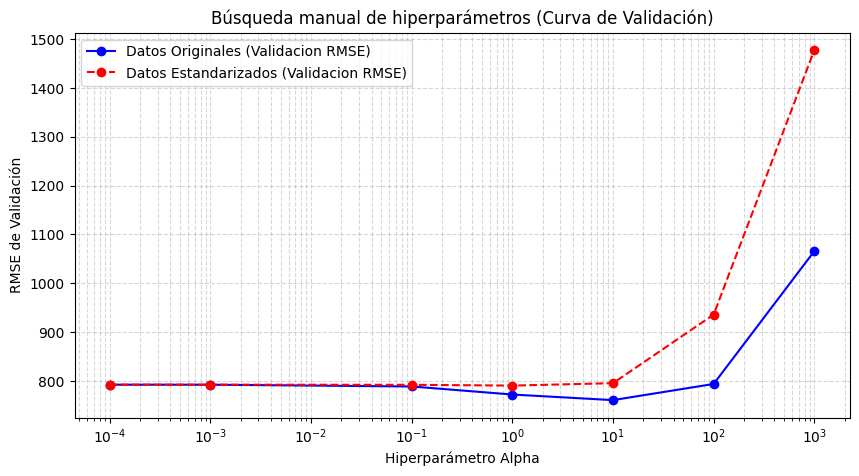

In [ ]:
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_squared_error
import numpy as np
import matplotlib.pyplot as plt

# Definir el hiperparámetro alphas localmente para asegurar su ejecución
alphas = [0.0001, 0.001, 0.1, 1, 10, 100, 1000]

# Obtener la media y desviación estándar del nuevo conjunto de entrenamiento
mu_nuevo = X_train.mean()
sigma_nuevo = X_train.std(ddof=1)

# Estandarizar correctamente los conjuntos de entrenamiento y validación de esta partición
X_train_std_correcto = (X_train - mu_nuevo) / sigma_nuevo
X_val_std_correcto = (X_val - mu_nuevo) / sigma_nuevo

# Listas para guardar las métricas de validación
validation_rmse_orig = []
validation_rmse_std = []

# Bucle de validación manual
for value in alphas:
    # --- 1. MODELO ORIGINAL ---
    modelo_orig = Ridge(alpha=value)
    modelo_orig.fit(X_train, y_train)

    # Evaluar con datos de validación originales
    y_val_pred_orig = modelo_orig.predict(X_val)
    rmse_orig = np.sqrt(mean_squared_error(y_val, y_val_pred_orig))
    validation_rmse_orig.append(rmse_orig)

    # --- 2. MODELO ESTANDARIZADO ---
    model_std = Ridge(alpha=value)
    model_std.fit(X_train_std_correcto, y_train)

    # Evaluar con datos de validación estandarizados
    y_val_pred_std = model_std.predict(X_val_std_correcto)
    rmse_std = np.sqrt(mean_squared_error(y_val, y_val_pred_std))
    validation_rmse_std.append(rmse_std)

# Encontrar el mejor alpha para cada caso
best_idx_orig = np.argmin(validation_rmse_orig)
best_alpha_orig = alphas[best_idx_orig]

best_idx_std = np.argmin(validation_rmse_std)
best_alpha_std = alphas[best_idx_std]

# Imprimir resultados del proceso manual
print("\t --- RESULTADOS DE VALIDACIÓN MANUAL CORREGIDOS ---")
print("\n"+"=x"*40+"\n")
for val, r_orig, r_std in zip(alphas, validation_rmse_orig, validation_rmse_std):
    print(f"Alpha: {val:<8} | RMSE Orig: {r_orig:.2f} | RMSE Std: {r_std:.2f}")

print("\n"+"=x"*40)
print(f"\n + Mejor Alpha Original: {best_alpha_orig} (RMSE: {validation_rmse_orig[best_idx_orig]:.4f})")
print(f" + Mejor Alpha Estandarizado: {best_alpha_std} (RMSE: {validation_rmse_std[best_idx_std]:.4f})")
print("\n"+"=x"*40+"\n")

# Graficar el comportamiento de alphas vs RMSE de validación
plt.figure(figsize=(10, 5))
plt.plot(alphas, validation_rmse_orig, 'o-', label='Datos Originales (Validacion RMSE)', color='blue')
plt.plot(alphas, validation_rmse_std, 'o--', label='Datos Estandarizados (Validacion RMSE)', color='red')
plt.xscale('log')
plt.xlabel('Hiperparámetro Alpha')
plt.ylabel('RMSE de Validación')
plt.title('Búsqueda manual de hiperparámetros (Curva de Validación)')
plt.grid(True, which="both", ls="--", alpha=0.5)
plt.legend()
plt.show()

## prediccion

In [ ]:
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
from sklearn.linear_model import Ridge
import numpy as np

# 0. Estandarizar correctamente el conjunto de prueba (usando mu_nuevo y sigma_nuevo del entrenamiento actual)
X_test_std_correcto = (X_test - mu_nuevo) / sigma_nuevo

# --- MODELO ORIGINAL ---
model_orig_final = Ridge(alpha=10)
model_orig_final.fit(X_train, y_train)

y_test_pred = model_orig_final.predict(X_test)

r2 = r2_score(y_test, y_test_pred)
mae = mean_absolute_error(y_test, y_test_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_test_pred))

# --- MODELO ESTANDARIZADO ---
model_std_final = Ridge(alpha=1)
model_std_final.fit(X_train_std_correcto, y_train)

y_test_pred_std = model_std_final.predict(X_test_std_correcto)

r2_std = r2_score(y_test, y_test_pred_std)
mae_std = mean_absolute_error(y_test, y_test_pred_std)
rmse_std = np.sqrt(mean_squared_error(y_test, y_test_pred_std))

# --- REPORTE DE RESULTADOS ---
print("--- RENDIMIENTO RIDGE ORIGINAL (TEST) ---")
print(" + R²   =", round(r2, 3))
print(" + MAE  =", round(mae, 2), "mD")
print(" + RMSE =", round(rmse, 2), "mD")

print("\n--- RENDIMIENTO RIDGE ESTANDARIZADO (TEST) ---")
print(" + R²   =", round(r2_std, 3))
print(" + MAE  =", round(mae_std, 2), "mD")
print(" + RMSE =", round(rmse_std, 2), "mD")

--- RENDIMIENTO RIDGE ORIGINAL (TEST) ---
 + R²   = 0.812
 + MAE  = 608.96 mD
 + RMSE = 781.16 mD

--- RENDIMIENTO RIDGE ESTANDARIZADO (TEST) ---
 + R²   = 0.794
 + MAE  = 634.15 mD
 + RMSE = 819.38 mD


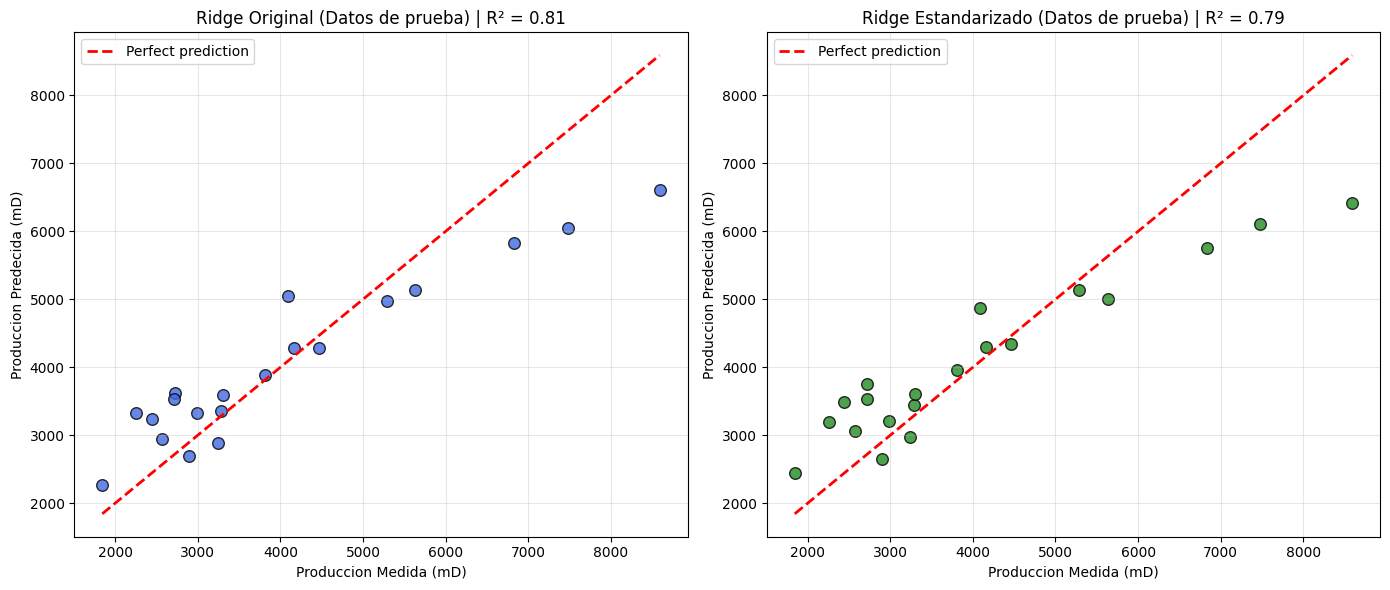

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# Crear la figura con dos subgráficos lado a lado
fig, axs = plt.subplots(1, 2, figsize=(14, 6))

# --- 1. Gráfica para Ridge Original ---
min_val_orig = min(y_test.min(), y_test_pred.min())
max_val_orig = max(y_test.max(), y_test_pred.max())

axs[0].scatter(y_test, y_test_pred, s=70, edgecolor="black", color="royalblue", alpha=0.8)
axs[0].plot([min_val_orig, max_val_orig], [min_val_orig, max_val_orig], "r--", linewidth=2, label="Perfect prediction")
axs[0].set_xlabel("Produccion Medida (mD)")
axs[0].set_ylabel("Produccion Predecida (mD)")
axs[0].set_title(f"Ridge Original (Datos de prueba) | R² = {r2:.2f}")
axs[0].grid(alpha=0.3)
axs[0].legend()

# --- 2. Gráfica para Ridge Estandarizado ---
min_val_std = min(y_test.min(), y_test_pred_std.min())
max_val_std = max(y_test.max(), y_test_pred_std.max())

axs[1].scatter(y_test, y_test_pred_std, s=70, edgecolor="black", color="forestgreen", alpha=0.8)
axs[1].plot([min_val_std, max_val_std], [min_val_std, max_val_std], "r--", linewidth=2, label="Perfect prediction")
axs[1].set_xlabel("Produccion Medida (mD)")
axs[1].set_ylabel("Produccion Predecida (mD)")
axs[1].set_title(f"Ridge Estandarizado (Datos de prueba) | R² = {r2_std:.2f}")
axs[1].grid(alpha=0.3)
axs[1].legend()

plt.tight_layout()
plt.show()

### 3. CONCLUSIÓN Y REFLEXIÓN TÉCNICA

**Impacto físico-matemático de la regularización y la escala:**
El algoritmo Ridge añade una penalización a la sumatoria de los coeficientes al cuadrado ($\alpha \sum \beta_j^2$). En los **datos originales**, como las escalas no están ajustadas, una variable con valores enormes (por ejemplo la Presión) genera de forma natural un coeficiente ($\beta$) muy pequeño; por lo tanto, el algoritmo Ridge casi no la penaliza. En contraste, las variables como el Skin (Daño), que se manejan en unidades o decimales, requieren un $\beta$ más grande, atrayendo injustamente toda la fuerza de la penalización matemática.

Al **estandarizar** previamente los datos, democratizamos el modelo. Todas las variables (porosidad, permeabilidad, espesor) entran a la función de pérdida con el mismo peso inicial. Esto permite que el hiperparámetro $\alpha$ regule los coeficientes basándose en su verdadera correlación y covarianza con la producción, y no solo en el tamaño de sus unidades de medición.

A nivel práctico de la ingeniería petrolera, regresión Ridge estandarizada es fundamental para manejar campos con pozos altamente interconectados donde la presión y la permeabilidad pueden ser colineales ya que reduce la varianza del modelo, bajando la incertidumbre predictiva a futuro sin descartar ninguna variable por completo.

BIBLIOGRAFÍA

•Ahmed, T. (2018). Reservoir Engineering Handbook (5th ed.). Gulf Professional Publishing.

•James, G., Witten, D., Hastie, T., & Tibshirani, R. (2013). An Introduction to Statistical Learning with Applications in R. Springer. (Capítulo 6: Linear Model Selection and Regularization).

•Hastie, T., Tibshirani, R., & Friedman, J. (2009). The Elements of Statistical Learning. Springer.